<a href="https://colab.research.google.com/github/DLO-4-ya/Probabilidad-y-Estadistica/blob/main/Unidad_6/practica_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Probabilidad y Estadistica**
#**Unidad 6**

##practica final: **base de datos sobre pruebas realizadas por COVID**
##entrega: jueves 26 de noviembre de 2026
**docente:** dr jose gabriel rodriguez rivas

**integrantes del equipo:**
Oliver Giovanni Hernandez Castro,
Dante Rucvalcaba Martinez

In [11]:
from google.colab import drive
import os
drive.mount('/content/drive')
ruta_base = '/content/drive/MyDrive'
for root, dirs, files in os.walk(ruta_base):
    for file in files:
        if file.endswith(('.csv', '.zip', '.txt')):
            ruta_completa = os.path.join(root, file)
            tamaño_mb = os.path.getsize(ruta_completa) / (1024 * 1024)
            if tamaño_mb > 100:
                print(f"Archivo encontrado: {ruta_completa} ({tamaño_mb:.2f} MB)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivo encontrado: /content/drive/MyDrive/covid2020-2021-codificado.csv (1540.48 MB)


In [12]:
import pandas as pd
ruta_archivo = '/content/drive/MyDrive/covid2020-2021-codificado.csv'
muestra = pd.read_csv(ruta_archivo, nrows=5, encoding='latin1')
print("Columnas disponibles:")
print(list(muestra.columns))

Columnas disponibles:
['SECTOR', 'SEXO', 'ENTIDAD_NAC', 'TIPO_PACIENTE', 'FECHA_INGRESO', 'FECHA_DEF', 'INTUBADO', 'NEUMONIA', 'EDAD', 'EMBARAZO', 'INDIGENA', 'DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO', 'RESULTADO_ANTIGENO', 'UCI']


In [13]:
ruta_archivo = '/content/drive/MyDrive/covid2020-2021-codificado.csv'
columnas_necesarias = ['SEXO', 'ENTIDAD_NAC', 'TIPO_PACIENTE', 'FECHA_INGRESO', 'EDAD', 'EMBARAZO', 'INDIGENA', 'DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO', 'RESULTADO_ANTIGENO']
df = pd.read_csv(ruta_archivo, usecols=columnas_necesarias, encoding='latin1', low_memory=False)
print(f"Base cargada con éxito. Total de registros: {len(df):,}")
df.head()

Base cargada con éxito. Total de registros: 12,634,194


,SEXO,ENTIDAD_NAC,TIPO_PACIENTE,FECHA_INGRESO,EDAD,EMBARAZO,INDIGENA,DIABETES,EPOC,ASMA,HIPERTENSION,CARDIOVASCULAR,OBESIDAD,RENAL_CRONICA,TABAQUISMO,RESULTADO_ANTIGENO
0,Femenino,San Luis PotosÃ­,Ambulatorio,2020-12-06,55,No,No,Si,No,No,No,No,No,No,No,Pendiente
1,Masculino,San Luis PotosÃ­,Ambulatorio,2020-02-20,59,No aplica,No,No,No,No,No,No,No,No,No,Pendiente
2,Femenino,Jalisco,Ambulatorio,2020-04-22,42,No,No,No,No,Si,No,No,No,No,No,Pendiente
3,Masculino,Chihuahua,Ambulatorio,2020-07-28,35,No aplica,No,No,No,No,No,No,No,No,No,Pendiente
4,Masculino,Ciudad De MÃ©xico,Ambulatorio,2020-08-18,51,No aplica,No,No,No,No,Si,No,No,No,No,Pendiente


In [27]:
print('Estadistica Descriptiva')
print("\nRESULTADO DE ANTIGENO")
print(df['RESULTADO_ANTIGENO'].value_counts(dropna=False))

print("\nTIPO DE PACIENTE")
print(df['TIPO_PACIENTE'].value_counts(dropna=False))

print("\nEMBARAZO")
print(df['EMBARAZO'].value_counts(dropna=False))

print("\nINDIGENA")
print(df['INDIGENA'].value_counts(dropna=False))

Estadistica Descriptiva

RESULTADO DE ANTIGENO
RESULTADO_ANTIGENO
Negativo     5853547
Pendiente    5005939
Positivo     1774708
Name: count, dtype: int64

TIPO DE PACIENTE
TIPO_PACIENTE
Ambulatorio      11543303
Hospitalizado     1090891
Name: count, dtype: int64

EMBARAZO
EMBARAZO
No                 6483614
No aplica          5985456
Si                  122583
Se ignora            42529
No especificado         12
Name: count, dtype: int64

INDIGENA
INDIGENA
NaN                8765798
No                 3665974
No especificado     167182
Si                   35240
Name: count, dtype: int64


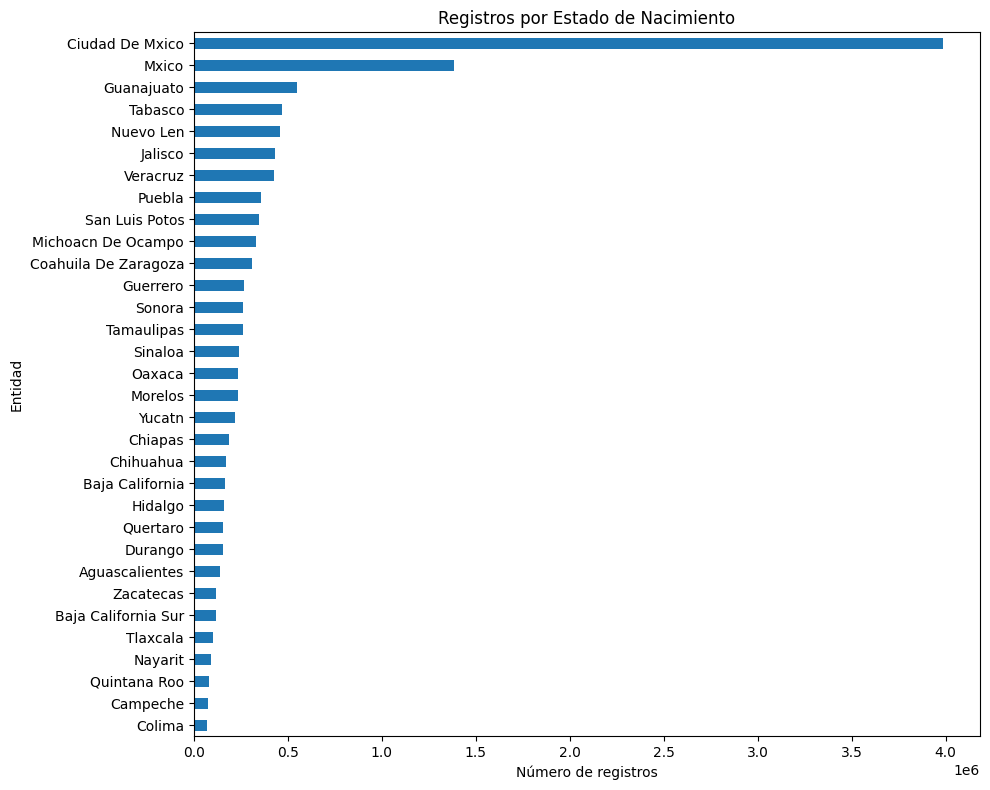

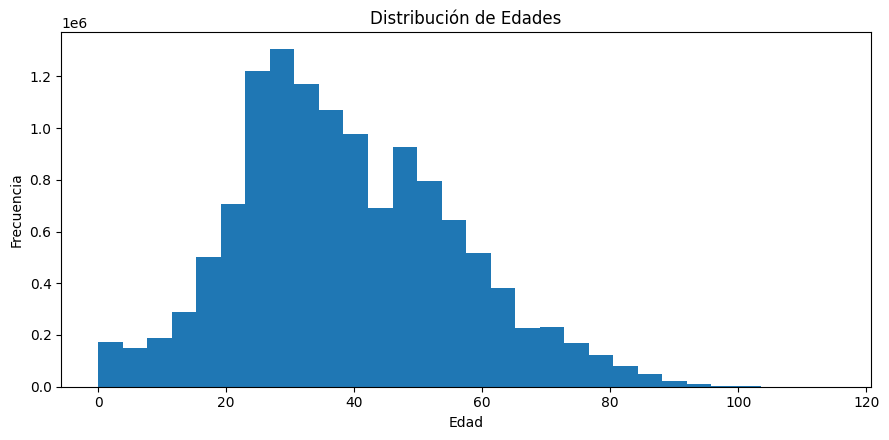

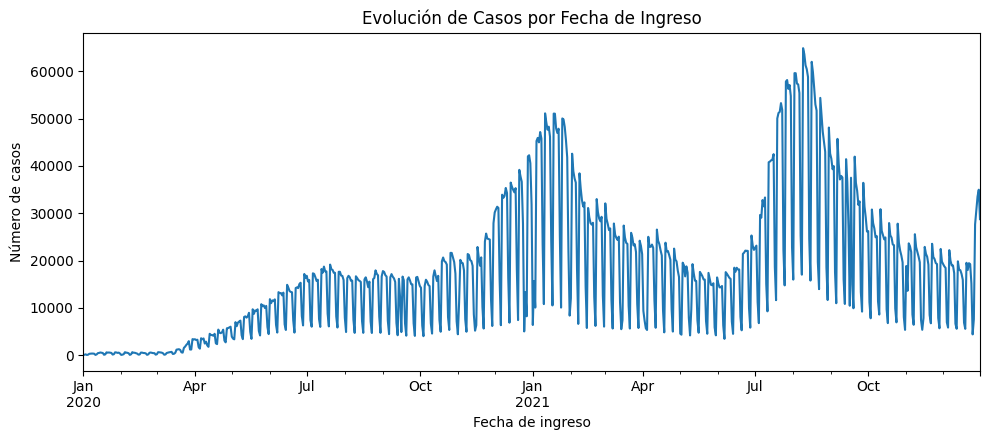

In [28]:
df_estados = df[~df['ENTIDAD_NAC'].isin([97, 98, 99, '97', '98', '99'])]
conteo_estados = df_estados['ENTIDAD_NAC'].value_counts().sort_values(ascending=True)

plt.figure(figsize=(10, 8))
conteo_estados.plot(kind='barh')
plt.title('Registros por Estado de Nacimiento')
plt.xlabel('Número de registros')
plt.ylabel('Entidad')
plt.tight_layout()
plt.show()


edades_validas = pd.to_numeric(df['EDAD'], errors='coerce').dropna()
edades_validas = edades_validas[(edades_validas >= 0) & (edades_validas <= 115)]

plt.figure(figsize=(9, 4.5))
plt.hist(edades_validas, bins=30)
plt.title('Distribución de Edades')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

fechas = pd.to_datetime(df['FECHA_INGRESO'], errors='coerce').dropna()
evolucion_diaria = fechas.value_counts().sort_index()
plt.figure(figsize=(10, 4.5))
evolucion_diaria.plot(kind='line')
plt.title('Evolución de Casos por Fecha de Ingreso')
plt.xlabel('Fecha de ingreso')
plt.ylabel('Número de casos')
plt.tight_layout()
plt.show()

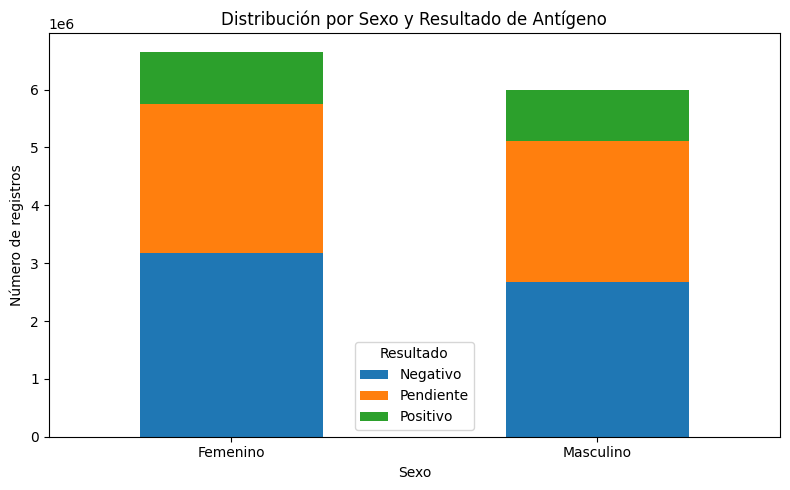

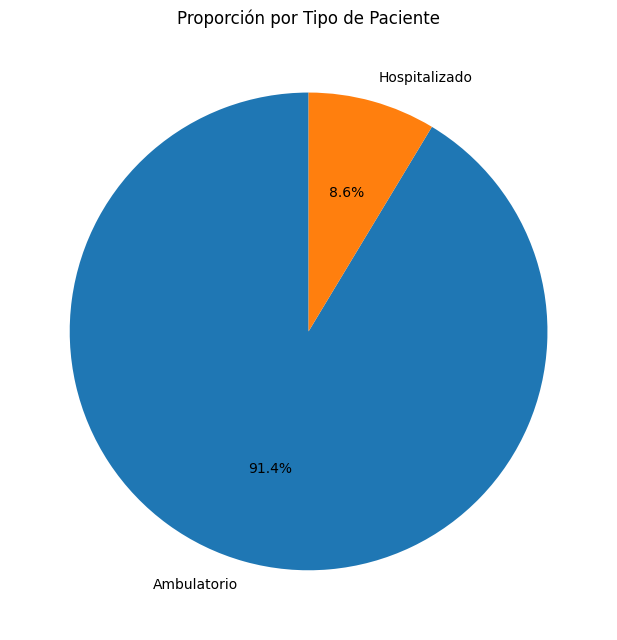

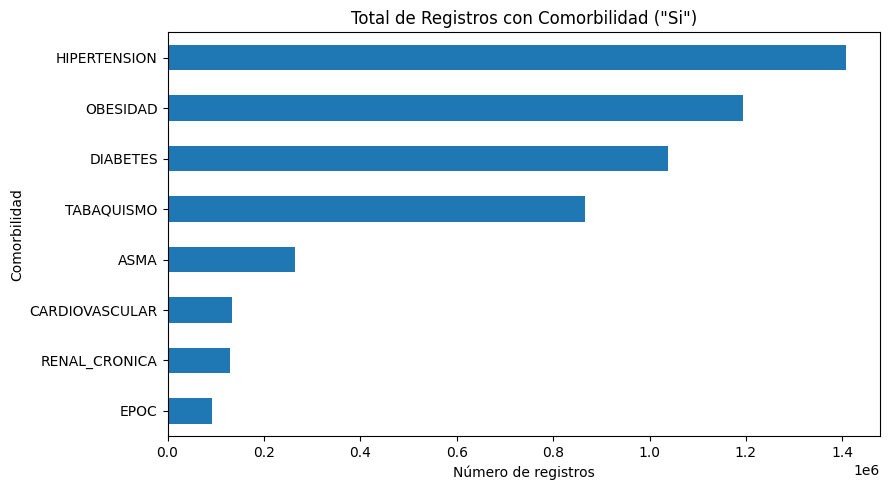

In [30]:

cruce_sexo_res = pd.crosstab(df['SEXO'], df['RESULTADO_ANTIGENO'])
cruce_sexo_res.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Distribución por Sexo y Resultado de Antígeno')
plt.xlabel('Sexo')
plt.ylabel('Número de registros')
plt.legend(title='Resultado')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

conteo_tipo_pac = df['TIPO_PACIENTE'].value_counts()
plt.figure(figsize=(6.5, 6.5))
plt.pie(
    conteo_tipo_pac,
    labels=conteo_tipo_pac.index,
    autopct='%1.1f%%',
    startangle=90)
plt.title('Proporción por Tipo de Paciente')
plt.tight_layout()
plt.show()

comorbilidades = ['DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO']
conteo_comorb = pd.Series({col: (df[col] == 'Si').sum() for col in comorbilidades}).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
conteo_comorb.plot(kind='barh')
plt.title('Total de Registros con Comorbilidad ("Si")')
plt.xlabel('Número de registros')
plt.ylabel('Comorbilidad')
plt.tight_layout()
plt.show()

In [18]:
print('Probabilidades por Comorbilidad e Interpretación Estadística \n')
comorbilidades = ['DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO']
total_general = len(df)
print(f"Total general de registros {total_general:,}\n")
prob_simple = {}
for col in comorbilidades:
    total_con_comorb = (df[col] == 'Si').sum()
    prob_simple[col] = total_con_comorb / total_general
df_prob_simple = pd.DataFrame({
    'Total_Si': [(df[col] == 'Si').sum() for col in comorbilidades],
    'Probabilidad_Simple': [prob_simple[col] for col in comorbilidades],
    'Porcentaje (%)': [prob_simple[col] * 100 for col in comorbilidades]
}, index=comorbilidades)
print("PROBABILIDAD SIMPLE POR COMORBILIDAD")
print(df_prob_simple.round(6))
df['ENTIDAD_NAC'] = df['ENTIDAD_NAC'].apply(
    lambda x: x.encode('latin1', errors='ignore').decode('utf-8', errors='ignore') if isinstance(x, str) else x
)
df_bin = pd.DataFrame({'ENTIDAD_NAC': df['ENTIDAD_NAC']})
for col in comorbilidades:
    df_bin[col] = (df[col] == 'Si').astype(int)
prob_condicional_entidad = df_bin.groupby('ENTIDAD_NAC')[comorbilidades].mean()

print("\nPROBABILIDAD CONDICIONAL POR ENTIDAD")
print(prob_condicional_entidad.round(6))

Probabilidades por Comorbilidad e Interpretación Estadística 

Total general de registros 12,634,194

PROBABILIDAD SIMPLE POR COMORBILIDAD
                Total_Si  Probabilidad_Simple  Porcentaje (%)
DIABETES         1038459             0.082194        8.219432
EPOC               92446             0.007317        0.731713
ASMA              263855             0.020884        2.088420
HIPERTENSION     1407779             0.111426       11.142610
CARDIOVASCULAR    134410             0.010639        1.063859
OBESIDAD         1193021             0.094428        9.442795
RENAL_CRONICA     129874             0.010280        1.027956
TABAQUISMO        865162             0.068478        6.847782

PROBABILIDAD CONDICIONAL POR ENTIDAD
                      DIABETES      EPOC      ASMA  HIPERTENSION  \
ENTIDAD_NAC                                                        
99                    0.024336  0.003881  0.026893      0.051137   
Aguascalientes        0.075668  0.008908  0.025213      0.116

Distribucion Normal
Probabilidad de que un estado tenga entre 2000 y 3000 casos: 0.507910
En porcentaje: 50.79%


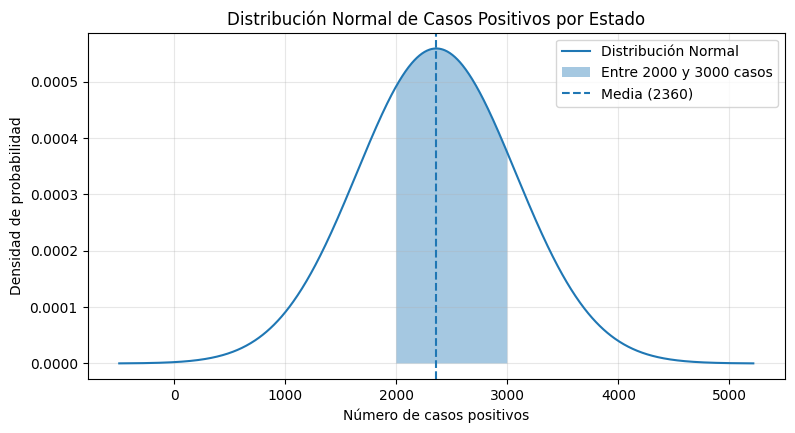

In [20]:
print('Distribucion Normal')
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
media = 2360
desv_std = 714

prob_entre_2000_y_3000 = norm.cdf(3000, loc=media, scale=desv_std) - norm.cdf(2000, loc=media, scale=desv_std)
print(f"Probabilidad de que un estado tenga entre 2000 y 3000 casos: {prob_entre_2000_y_3000:.6f}")
print(f"En porcentaje: {prob_entre_2000_y_3000 * 100:.2f}%")
x = np.linspace(media - 4 * desv_std, media + 4 * desv_std, 1000)
y = norm.pdf(x, loc=media, scale=desv_std)
plt.figure(figsize=(9, 4.5))
plt.plot(x, y, label='Distribución Normal')
x_area = np.linspace(2000, 3000, 400)
plt.fill_between(x_area, norm.pdf(x_area, loc=media, scale=desv_std), alpha=0.4, label='Entre 2000 y 3000 casos')
plt.axvline(media, linestyle='--', label=f'Media ({media})')
plt.title('Distribución Normal de Casos Positivos por Estado')
plt.xlabel('Número de casos positivos')
plt.ylabel('Densidad de probabilidad')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Interpretación General de Resultados

De los 12.6 millones registros que cargamos, la mayoría de pruebas de antígeno salieron negativas (5 millones), 5 millones quedaron pendientes y 1.7 millones positivas. Casi todos los pacientes fueron ambulatorios (11.5 millones) y 1 millon hospitalizados, además de 120 milembarazadas y 35 mil indígenas.

En las gráficas se ve que la CDMX y el Estado de México concentran más registros, la edad se carga bastante en adultos jóvenes y de mediana edad, las fechas marcan bien las olas de contagio y la gran mayoría del pastel es ambulatorio. En comorbilidades, hipertensión, obesidad y diabetes son las que más destacan tanto en probabilidad simple como cuando revisamos por estado, donde cambian los porcentajes según la entidad. En la distribución normal (media 2360, desviacuib estandar 714) la probabilidad de estar entre 2000 y 3000 casos salió de 50.79%

## Conclusiones Personales

Al principio costó un poco cargar y procesar el archivo porque son muchísimos datos y se trababa la memoria, pero agarrando solo las columnas que ocupábamos ya jaló bien. Con las gráficas y las probabilidades se entiende mucho mejor cómo se repartieron los casos y las enfermedades por estado sin tener que estar viendo tablas enormes